# 8. Butadiene: Transition State for Rotation

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/08-Butadiene/081-Butadiene.ipynb)
:::

We expect butadiene to prefer a **flat** *syn* or *anti* conformation. These **two** possible **conformations** are designated "*s-cis*" and "*s-trans*". The "s" refers to the &sigma; bond involved. There should be an energy maximum when the **torsion** angle is 90&deg; due to the loss of **conjugation** when the two &pi; bonds are orthogonal.

The **change** in electronic structure as the central bond rotates is similar to a chemical **reaction**. Molecular orbitals are being substantially changed and we proceed from one stable conformation **to another**. We could view the highest energy point in this potential energy profile for rotation as a **transition state** in the change from *s-cis* to *s-trans*. In this chapter, we will explore the **rotational potential energy profile** for butadiene and introduce the concept of **optimizing** a transition state structure.

We will **model** butadiene and determine its most stable **configuration** in the *s-trans* and *s-cis* rotational conformers. We will then estimate the energy **difference** between the two conformers and use this value to estimate the equilibrium constant between the two states. We will **scan** through a rotation of the central bond to locate the highest energy structure along the path. We will use the **energy barrier** to calculate an estimate for the rate of the process for rotating between the conformations and draw a **conclusion** as to whether there is a barrier to rotation.

Finally we will use an optimized **structure** that is near the energy **maximum** as a starting point for **optimizing** the structure of the **transition state** for the bond rotation.

## Learning Goals

In this exercise, we will accomplish the following…

1.	**Build** butadiene with a *Z-matrix* in a *Python* function and **optimize** the *s-trans* and *s-cis* conformers.
2.	**Read** a *Psi4* output file and find the important parts: the symmetry, the basis set, the energy at each step, the convergence checks and the final structure.
3.	**Recognize** when **symmetry** traps an optimization on a hilltop, and **break** the symmetry to escape.
4.	**Freeze** the central C&ndash;C torsion and **scan** it to build a rotational energy profile.
5.	**Calculate** the vibrational **frequencies** near the top of the barrier and find the **imaginary** vibration.
6.	**Optimize** a **transition state** structure and confirm it with a frequency calculation.
7.	**Estimate** an equilibrium constant and a rate constant from the calculated energies.

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Setting Up the Notebook

As in the previous chapters, the hidden **first code cell** imports *Psi4*, *py3Dmol*, *NumPy*, *pandas* and *Matplotlib* and applies the plot **style sheet**. You will see it when you open the notebook in *Jupyter*, *Visual Studio Code* or *Google Colab*.

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* with *conda* (*Psi4* cannot be installed with *pip*), install *py3Dmol* with *pip*, and download the plot style sheets from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

Next, we tell *Psi4* how much of the computer it may use, and set the options that we will need in this chapter.

In [2]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"scf_type": "pk"})


  Memory set to   3.725 GiB by Python driver.
  Threads set to 4 by Python driver.


| Line | Notes |
| :---- | :---- |
| `"scf_type": "pk"` | Calculate the electron repulsion integrals **exactly**, as in the previous chapters. |

We will add the options for **freezing** a coordinate and for finding a **transition state** later in the chapter, when we need them.

### Some Helpful Tools

We will reuse the functions from the previous chapters, and add one new one, `show_vibration()`, that **animates** a vibration. In the webbook, click on the code section to expand it. Run the cell below once.

In [3]:
def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def dihedral(mol, i, j, k, l):
    xyz = mol.geometry().np
    b1 = xyz[j] - xyz[i]
    b2 = xyz[k] - xyz[j]
    b3 = xyz[l] - xyz[k]
    n1 = np.cross(b1, b2)
    n2 = np.cross(b2, b3)
    x = np.dot(n1, n2)
    y = np.dot(np.cross(n1, n2), b2) / np.linalg.norm(b2)
    return np.degrees(np.arctan2(y, x))

def plot_history(history, title):
    energies = np.array(history["energy"])
    delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
    steps = np.arange(1, len(energies) + 1)

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
    ax.plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    ax.set_xticks(steps)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel(r"$E - E_{final}$ (kJ/mol)")
    ax.set_title(title)
    plt.show()

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

def show_vibration(wfn, mode=0):
    vib = wfn.frequency_analysis
    vibrations = [i for i, kind in enumerate(vib["TRV"].data) if kind == "V"]
    vector = vib["x"].data[:, vibrations[mode]].reshape(-1, 3)
    mol = wfn.molecule()
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms

    lines = [str(mol.natom()), "normal mode"]
    for i in range(mol.natom()):
        x, y, z = xyz[i]
        dx, dy, dz = vector[i]
        lines.append(f"{mol.symbol(i)} {x:.6f} {y:.6f} {z:.6f} {dx:.6f} {dy:.6f} {dz:.6f}")

    view = py3Dmol.view(width=400, height=300)
    view.addModel("\n".join(lines), "xyz", {"vibrate": {"frames": 10, "amplitude": 1.0}})
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.animate({"loop": "backAndForth"})
    view.zoomTo()
    view.show()

| Function | What it does |
| :---- | :---- |
| `show_molecule(mol)` | Draws the molecule with *py3Dmol*. |
| `bond_length(mol, i, j)` | The distance between atoms `i` and `j` in **&Aring;ngstroms**. |
| `bond_angle(mol, i, j, k)` | The angle `i`&ndash;`j`&ndash;`k` in **degrees**, with `j` in the middle. |
| `dihedral(mol, i, j, k, l)` | The **torsion** (dihedral) angle `i`&ndash;`j`&ndash;`k`&ndash;`l` in degrees, looking down the `j`&ndash;`k` bond. |
| `plot_history(history, title)` | **Plots** the energy at each step of an optimization, relative to the final energy, in *kJ/mol*. |
| `search_file(filename, text)` | **Prints** every line of a text file that contains `text`, with its line number. |
| `show_vibration(wfn, mode)` | **Animates** one vibration from a frequency calculation. `mode=0` is the vibration with the lowest frequency, which is the **imaginary** one if there is one. |

```{note}
*Python* counts atoms from **zero**. The *Z-matrix*, and the *Psi4* options that freeze coordinates, count from **one**. The central torsion is 4,3,2,1 in the *Z-matrix* and `dihedral(mol, 3, 2, 1, 0)` in *Python*.
```

## Optimizing the *s-trans* Conformer

We will begin with a **review** of building molecules and optimizing structure. We will **build** both *s-cis* and *s-trans*-butadiene and attempt to **optimize** the structures. We will learn about some pitfalls along the way. Let us now **begin** with *s-trans*.

### Building *s-trans*-Butadiene

In the *GAMESS* version of this book, we clicked atoms together in the *MacMolPlt* builder and let it write a *Z-matrix* for us. We will use that **same** *Z-matrix* here, typed into a *Python* function as we did for butane. The four carbons come first. The fourth line puts carbon \#4 at a **torsion** of 180&deg; from carbon \#1, looking down the C2&ndash;C3 bond. That is the *s-trans* conformation, and it is the angle we will be rotating for the rest of the chapter. The starting bond lengths (1.54 &Aring; for C&ndash;C and 1.14 &Aring; for C&ndash;H) are a rough sketch. The optimizer will fix them.

The function takes three arguments. `torsion` is the central 4,3,2,1 torsion angle. `tweak` pushes all the other torsions a few degrees away from flat (we will need this later). `symmetry` is the point group that we allow *Psi4* to use.

In [4]:
def make_butadiene(torsion, tweak=0.0, symmetry="c1"):
    return psi4.geometry(f'''
0 1
C
C   1    1.54000
C   2    1.54000  1 120.0000
C   3    1.54000  2 120.0000  1 {torsion}
H   1    1.14000  2 120.0000  3 {0 + tweak}
H   1    1.14000  5 120.0000  2 {180 - tweak}
H   2    1.14000  1 120.0000  3 {180 - tweak}
H   3    1.14000  4 120.0000  2 {180 - tweak}
H   4    1.14000  3 120.0000  7 {0 + tweak}
H   4    1.14000  9 120.0000  3 {180 - tweak}
symmetry {symmetry}
''')

trans = make_butadiene(180.0, symmetry="c2h")
trans.update_geometry()

print("Full point group:         ", trans.get_full_point_group())
print("Computational point group:", trans.schoenflies_symbol())
print(f"C4-C3-C2-C1 torsion: {dihedral(trans, 3, 2, 1, 0):.2f} degrees")
show_molecule(trans)

Full point group:          C2h
Computational point group: c2h
C4-C3-C2-C1 torsion: 180.00 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `def make_butadiene(torsion, tweak=0.0, symmetry="c1"):` | A function that returns a butadiene **molecule**. `tweak` and `symmetry` have **default** values, so we only need to give them when we want something different. |
| `{0 + tweak}`, `{180 - tweak}` | The other five torsions. With `tweak=0.0` they are exactly 0&deg; or 180&deg; and the molecule is **flat**. |
| `symmetry {symmetry}` | The point group *Psi4* will use. `c1` means no symmetry. |
| `make_butadiene(180.0, symmetry="c2h")` | Flat *s-trans*-butadiene belongs to the *C<sub>2h</sub>* point group. We let *Psi4* **use** that symmetry. |

The flat *s-trans* structure has a two-fold rotation axis, a mirror plane (the plane of the molecule) and a centre of inversion. That is the *C<sub>2h</sub>* point group, and *Psi4* found it. The torsion is 180&deg;.

```{admonition} The basis set: 3-21G or 3-21G*?
:class: dropdown
In the *GAMESS* book, I asked *MacMolPlt* for the 3-21G basis set with one set of *d* polarization functions on heavy atoms (`GBASIS=N21 NGAUSS=3 NDFUNC=1`) and called it 3-21G<sup>*</sup>. The *GAMESS* manual tells us that for `GBASIS=N21` the word "heavy" means **sodium and beyond**. Carbon got **no** *d* functions. That is the Pople convention for 3-21G<sup>(*)</sup>, where only second-row atoms are polarized. The *GAMESS* log file confirms it: 48 basis functions, exactly the number for plain 3-21G on C<sub>4</sub>H<sub>6</sub> (9 for each carbon and 2 for each hydrogen). So the *Psi4* equivalent is simply `hf/3-21g`, and we can compare energies with the *GAMESS* results directly.
```

### Optimizing the Structure

Now we will feed the **molecule** to *Psi4*. The job will run and produce an output file that will contain a description of the **structure** with the minimum calculated overall energy. This might be the most **stable** structure for our molecule.

In [5]:
psi4.set_output_file("butadiene_trans.out", False)

E_trans, hist_trans = psi4.optimize("hf/3-21g", molecule=trans, return_history=True)

print(f"Final energy: {E_trans:.8f} Hartree")
print("Steps taken: ", len(hist_trans["energy"]))
print(f"C4-C3-C2-C1 torsion: {dihedral(trans, 3, 2, 1, 0):.2f} degrees")
print(f"C1=C2 {bond_length(trans, 0, 1):.4f}   C2-C3 {bond_length(trans, 1, 2):.4f}   C3=C4 {bond_length(trans, 2, 3):.4f} Angstrom")
print(f"C1-C2-C3 angle: {bond_angle(trans, 0, 1, 2):.2f} degrees")
show_molecule(trans)

Optimizer: Optimization complete!
Final energy: -154.05945628 Hartree
Steps taken:  8
C4-C3-C2-C1 torsion: 180.00 degrees
C1=C2 1.3203   C2-C3 1.4674   C3=C4 1.3203 Angstrom
C1-C2-C3 angle: 123.98 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `"hf/3-21g"` | Hartree-Fock with the small **3-21G** basis set. This is a low level of theory and is suitable for quick **calculations** that we want to be able to use and interpret during class. |
| `bond_length(trans, 0, 1)` | The C1=C2 bond. Remember that *Python* atom `0` is *Z-matrix* atom \#1. |

*Psi4* finished in 8 steps with an energy of &minus;154.05945628 Hartree. The C=C double bonds are 1.3203 &Aring; and the central C&ndash;C single bond is 1.4674 &Aring;. The C&ndash;C&ndash;C angle is 123.98&deg; and the torsion is still 180&deg;.

*GAMESS* took 8 steps (plus the starting point) and found &minus;154.0594565686 Hartree, with C=C bonds of 1.3204 &Aring;, a C&ndash;C bond of 1.4671 &Aring; and a C&ndash;C&ndash;C angle of 123.96&deg;. The two energies differ by only 3 &times; 10<sup>&minus;7</sup> Hartree, and the bond lengths agree to within 0.0003 &Aring;. Same method, same basis set, same starting structure, same answer. *Psi4* even needed one energy calculation fewer: *GAMESS* counts the starting point as `NSERCH` 0 and made nine energy calculations, while *Psi4* counts the starting point as step 1 and made eight.

### The Output File

*Psi4* wrote everything it did into `butadiene_trans.out`, beside this notebook. In the *GAMESS* book I presented a 3000 line log file in very tiny print with the important sections highlighted. Let us **tour** the *Psi4* output file with `search_file()` instead. First, the **header** and the **setup**. *Psi4* tells us which point group it is using and how many basis functions it built.

In [6]:
search_file("butadiene_trans.out", "Psi4: An Open-Source")
search_file("butadiene_trans.out", "Running in")
search_file("butadiene_trans.out", "Number of basis functions")

     3:           Psi4: An Open-Source Ab Initio Electronic Structure Package
    98:   Running in c2h symmetry.
   545:   Running in c2h symmetry.
  1002:   Running in c2h symmetry.
  1459:   Running in c2h symmetry.
  1916:   Running in c2h symmetry.
  2373:   Running in c2h symmetry.
  2829:   Running in c2h symmetry.
  3285:   Running in c2h symmetry.
   126:     Number of basis functions: 48
   139:       Number of basis functions:        48
   307:     Number of basis functions: 48
   573:     Number of basis functions: 48
   596:       Number of basis functions:        48
   764:     Number of basis functions: 48
  1030:     Number of basis functions: 48
  1053:       Number of basis functions:        48
  1221:     Number of basis functions: 48
  1487:     Number of basis functions: 48
  1510:       Number of basis functions:        48
  1678:     Number of basis functions: 48
  1944:     Number of basis functions: 48
  1967:       Number of basis functions:        48
  2135:  

| Line | Notes |
| :---- | :---- |
| `"Running in"` | The line that reports the **point group** used for each energy calculation. |
| `"Number of basis functions"` | The size of the **basis set**. |

The first few lines of the file are the *Psi4* **header** with credits and references, and information about the computer and the number of threads. Then, for **each step** of the optimization, *Psi4* reports the structure (`==> Geometry <==`), the point group, the basis set and then performs an **energy** calculation. Every step ran in *c2h* symmetry, and every step used 48 basis functions, the same as *GAMESS*.

The energy calculation is followed by a calculation of the first derivative of the energy, the **gradient**. The gradient tells *Psi4* which **direction** to change bond lengths and angles to follow a **downhill** slope in the energy function. *Psi4*'s optimizer, *optking*, then takes the structure and changes the **bond lengths and angles** according to the gradient. It takes baby steps so as not to overshoot a possible minimum-energy destination. After applying these small changes, *Psi4* performs another energy and gradient **calculation**.

This process is **repeated again and again**. The energy and gradient are calculated and then that information is used to change the structure along the downward slope of the energy function. We will repeat this process until the molecule is **no longer changing**. When the changes drop below a certain threshold value, the program will declare that a "stationary point" has been reached. This is the place where the **first derivative** of the energy function is **zero**. It is the bottom of a well or the peak of a hill. Since we have been following the gradient downwards, we will assume that we have reached a **minimum** in energy.

The energy is reported near the end of each step. In the *GAMESS* book we used *grep* to pull out the `NSERCH` lines. Here are the *Psi4* equivalents, the final SCF energy of each step and the *optking* **convergence** table.

In [7]:
search_file("butadiene_trans.out", "@RHF Final Energy")
search_file("butadiene_trans.out", "~")

   229:   @RHF Final Energy:  -153.95417626364463
   686:   @RHF Final Energy:  -154.04901438060867
  1143:   @RHF Final Energy:  -154.05549458649367
  1600:   @RHF Final Energy:  -154.05749558865062
  2057:   @RHF Final Energy:  -154.05841275071521
  2513:   @RHF Final Energy:  -154.05895190783653
  2969:   @RHF Final Energy:  -154.05944706044065
  3424:   @RHF Final Energy:  -154.05945627704625
   455: 	----------------------------------------------------------------------------------------------~
   456: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
   457: 	----------------------------------------------------------------------------------------------~
   458: 	  Convergence Criteria     1.00e-06 *    3.00e-04 *             o    1.20e-03 *             o~
   459: 	----------------------------------------------------------------------------------------------~
   460: 	     1    -153.95417626   -1.54e+02      1.63e-01      4.54e-02 o  

One `@RHF Final Energy` line for **each step**, and one line of the convergence table for each step. Each line of the table (marked with `~` at the end) gives the energy, the change in energy, the largest and the root-mean-square **force** and the largest and root-mean-square **displacement** of the step. A `*` means that the value has met its target. At the last step, step 8, the largest force (2.18 &times; 10<sup>&minus;4</sup>) and the largest displacement (6.03 &times; 10<sup>&minus;4</sup>) met their targets, but the energy change (&minus;9.22 &times; 10<sup>&minus;6</sup> Hartree) did **not**. That is enough. *Psi4* declares that it has found a **stationary point** when the largest force is below 3.0 &times; 10<sup>&minus;4</sup> **and either** the change in energy is below 1.0 &times; 10<sup>&minus;6</sup> Hartree **or** the largest displacement is below 1.2 &times; 10<sup>&minus;3</sup>. *GAMESS* used a different test: `OPTTOL=0.0001` requires the largest component of the gradient to be less than 0.0001 Hartree/Bohr and the root-mean-square gradient to be less than one third of that. *Psi4* stopped a little earlier, which is why its energy is a hair higher.

### Final Results

At the end of all this we have the **final structure** and the final energy value for that structure. Since we built the molecule with a *Z-matrix*, *Psi4* gives us back the *Z-matrix* with the **optimized values** filled in.

In [8]:
with open("butadiene_trans.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 18]))

    Final optimized geometry and variables:
    Molecular point group: c2h
    Full point group: C2h

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

    C       
    C             1    1.320324
    C             2    1.467394      1  123.979922
    C             3    1.320324      2  123.979922      1 -180.000000
    H             1    1.074282      2  121.794974      3   -0.000000
    H             1    1.072477      5  116.394433      2  180.000000
    H             2    1.075478      1  119.879284      3 -180.000000
    H             3    1.075478      4  119.879284      2  180.000000
    H             4    1.074282      3  121.794974      7   -0.000000
    H             4    1.072477      9  116.394433      3 -180.000000




| Line | Notes |
| :---- | :---- |
| `next(i for i, line in enumerate(lines) if ...)` | The line number of the **first** line that contains the text. We then print the 18 lines from there. |

The internal coordinates list the **bond lengths and angles**. The C=C bond lengths (2,1 and 4,3) are 1.320 &Aring; and the C&ndash;C bond length (3,2) is 1.467 &Aring;. The C&ndash;C&ndash;C angles are 123.98&deg; and the dihedral angle along the C&ndash;C bond (4,3,2,1) is 180&deg; (written as &minus;180&deg;, the same thing). The C&ndash;H bonds have shrunk from our generous 1.14 &Aring; to between 1.072 and 1.075 &Aring;. The molecule kept its *C<sub>2h</sub>* symmetry the whole way. From these internal coordinates, I can create a **diagram** of the optimized structure. See {numref}`fig8-1`.

```{figure} ../../images/Butadiene5.png
---
width: 500px
name: fig8-1
---
*The optimized structure of s-trans-butadiene, drawn from the internal coordinates in the output file (from the GAMESS book, whose numbers agree with the Psi4 result).*
```

Take note that the diagram in {numref}`fig8-1` was **constructed** by examining the **text** of the output file. We don't have to use a graphical interface. Often, using internal coordinates gives us **easy** access to structural details.

### The Energy at Each Step

We have the energy at each step waiting in the `hist_trans` dictionary. Let us make a **graph** of the relative energies. The energy is in Hartrees (*Ha*), a unit common in computational chemistry. There are 2625.5 *kJ/mol* in a Hartree. The left plot shows all steps and the right plot shows the energy from step 3 to the end.

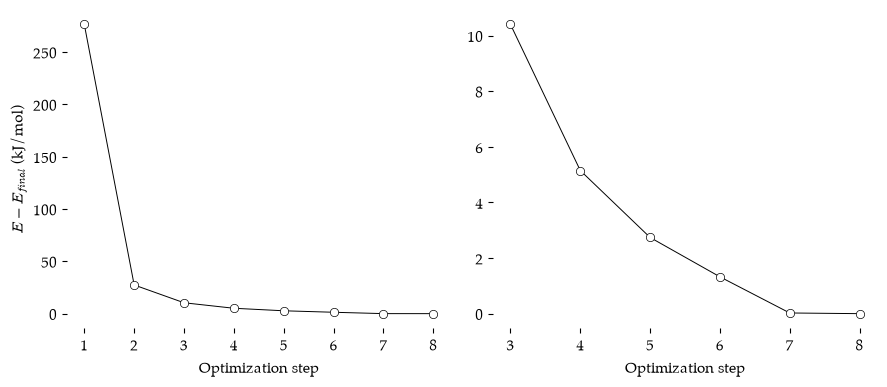

In [9]:
energies = np.array(hist_trans["energy"])
delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
steps = np.arange(1, len(energies) + 1)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))
for ax, first in zip(axs, [0, 2]):
    ax.plot(steps[first:], delta_E[first:], color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    ax.set_xticks(steps[first:])
    ax.set_xlabel("Optimization step")
axs[0].set_ylabel(r"$E - E_{final}$ (kJ/mol)")
plt.show()

| Line | Notes |
| :---- | :---- |
| `for ax, first in zip(axs, [0, 2]):` | Draws the **same** data on both panels. The left one starts at the first step (index `0`), the right one at step 3 (index `2`). |

The energy changes **quickly** in the first few steps and then we keep making **small changes** until *Psi4* halted the optimization. The first step alone dropped the energy by 249 *kJ/mol* (0.0948 Hartree). By step 7 we were within 0.03 *kJ/mol* of the final energy.

-----

## Optimized Geometry of the *s-cis* Conformer

Butadiene can **rotate** around the central C&ndash;C bond. It can exist as a *s-cis* or a *s-trans* conformer. The energy barrier is small and the central bond can easily rotate. We could calculate the **optimized** structure for the *s-cis* conformer and compare that energy to the *s-trans* conformer.

### Changing the Torsion

Let us rotate the central bond all the way around. The simplest way to do this is to **change** the 4,3,2,1 torsional angle from 180&deg; to 0&deg;. With our function, that is one number. The flat *s-cis* molecule belongs to the *C<sub>2v</sub>* point group.

In [10]:
cis_flat = make_butadiene(0.0, symmetry="c2v")

psi4.set_output_file("butadiene_cis_flat.out", False)

E_cis_flat, hist_cis_flat = psi4.optimize("hf/3-21g", molecule=cis_flat, return_history=True)

print(f"Final energy: {E_cis_flat:.8f} Hartree")
print("Steps taken: ", len(hist_cis_flat["energy"]))
print(f"C4-C3-C2-C1 torsion: {dihedral(cis_flat, 3, 2, 1, 0):.2f} degrees")
print(f"C1-C2-C3 angle: {bond_angle(cis_flat, 0, 1, 2):.2f} degrees")
show_molecule(cis_flat)

Optimizer: Optimization complete!
Final energy: -154.05394327 Hartree
Steps taken:  9
C4-C3-C2-C1 torsion: 0.00 degrees
C1-C2-C3 angle: 126.66 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

We see the torsion 4,3,2,1 value is **zero** in the optimized structure. *Psi4* took 9 steps and found an energy of &minus;154.05394327 Hartree (*GAMESS*: &minus;154.0539432855). Is the **electronic demand** to maximize planarity and &pi;-orbital overlap able to completely trump the **steric cost** of pushing the end groups into close proximity? I don't know about that. Look at the 3,2,1 bend. It represents the **angle** in the carbon chain. It is 126.66&deg;. This is much larger than the ideal 120&deg; angle. The bond angle is being **forced** open to relieve the steric clash between the ends. But is this the lowest energy structure for the *s-cis* form of butadiene? {numref}`fig8-2` shows a **diagram** for the result of this optimization.

```{figure} ../../images/Butadiene7.png
---
width: 500px
name: fig8-2
---
*Result of optimization of the flat s-cis conformer (from the GAMESS book; the Psi4 numbers agree).*
```

### Avoiding Traps and Pitfalls

The perfectly **flat** structure might be on a **maximum** energy point and unable to **snap out of it** because the gradients for the torsions are all calculated to be zero. Are we at a **peak** or in a valley?

Here we made the trap even **tighter** than in the *GAMESS* book. We told *Psi4* to use *C<sub>2v</sub>* symmetry. *Psi4* then only considers changes to the structure that **keep** that symmetry, and twisting the central bond would destroy it. The molecule was never allowed to leave the plane. *GAMESS* ran the same job without symmetry (`C1` in the `$DATA` group) and was trapped anyway, because in a perfectly flat molecule the forces that would twist it out of the plane are exactly **zero**.

### Breaking The Symmetry

Let's simply **set** the torsions to 5&deg; away from flat and then let the calculation run, with **no symmetry**. In the *GAMESS* book I also had to increase `NSTEP` from 20 to 100. The calculation was stopping at 20 steps, and if we stop on a count rather than when we find the stationary point we won't be at the optimized **destination**. *Psi4* allows 50 steps by default (the `geom_maxiter` option), which will be enough here.

I'm going to do the same with the *s-trans* conformer as well. In that calculation we had set the 4,3,2,1 torsion to 180&deg; and it had remained there. We will **tweak** all the torsions by 5&deg; there as well. First the *s-cis* conformer…

In [11]:
cis = make_butadiene(5.0, tweak=5.0)

psi4.set_output_file("butadiene_cis.out", False)

E_cis, hist_cis = psi4.optimize("hf/3-21g", molecule=cis, return_history=True)

print(f"Final energy: {E_cis:.8f} Hartree")
print("Steps taken: ", len(hist_cis["energy"]))
print(f"C4-C3-C2-C1 torsion: {dihedral(cis, 3, 2, 1, 0):.2f} degrees")
print(f"C1-C2-C3 angle: {bond_angle(cis, 0, 1, 2):.2f} degrees")
show_molecule(cis)

Optimizer: Optimization complete!
Final energy: -154.05514025 Hartree
Steps taken:  20
C4-C3-C2-C1 torsion: 38.15 degrees
C1-C2-C3 angle: 124.80 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `make_butadiene(5.0, tweak=5.0)` | The central torsion starts at 5&deg; and all the other torsions start 5&deg; away from flat (5&deg; or 175&deg;). These are the same starting values as in the *GAMESS* book. We leave `symmetry` at its default, `c1`. |

### The True *s-cis* Structure

Once the **symmetry** of the flat structure was **broken**, the molecule had a whole other dimension to explore and it took 20 steps to reach a minimum energy (*GAMESS* took 32). The energy is &minus;154.05514025 Hartree (*GAMESS*: &minus;154.0551401544). Most of the torsions are almost flat, as expected. However, the central C&ndash;C bond **settled** to a torsion angle of 38.15&deg;! That is very not flat. The *sp<sup>2</sup>* hybridization and the orbital overlap demand a flat structure, but the **realities** of steric clash push against that goal. We ended up being pushed out of planar as we maximized electron delocalization and minimized steric clash. It's called **compromise** and it's how the world gets along.

Let us plot the energy and the largest component of the **gradient** at each step.

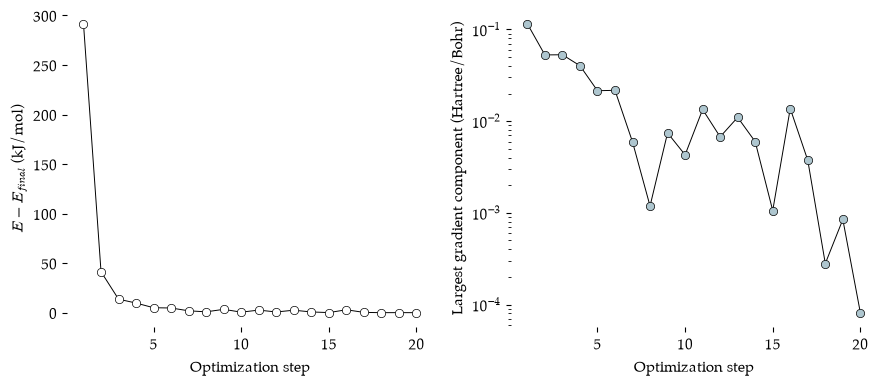

In [12]:
energies = np.array(hist_cis["energy"])
delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
max_grad = [np.max(np.abs(g)) for g in hist_cis["gradient"]]
steps = np.arange(1, len(energies) + 1)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))

axs[0].plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
axs[0].set_xlabel("Optimization step")
axs[0].set_ylabel(r"$E - E_{final}$ (kJ/mol)")

axs[1].plot(steps, max_grad, color="black", linewidth=0.7, marker="o",
            markerfacecolor="#AEC6CF", markeredgecolor="black", markeredgewidth=0.5)
axs[1].set_yscale("log")
axs[1].set_xlabel("Optimization step")
axs[1].set_ylabel("Largest gradient component (Hartree/Bohr)")

plt.show()

You can see that the **path** to lowest energy was **not** as **smooth** when there are more options to explore. *Psi4* took a **wrong turn** several times. The energy went **up** at steps 9, 11, 13, 16 and 19, by as much as 2.9 *kJ/mol* (at step 16). The changes applied according to the gradients were too large and we went **too far** along one of the energy gradients at various points. There are 24 bond lengths, angles and torsions that are being adjusted, and the flat directions of the torsions make the journey long. But *Psi4* did find a **minimum** in the end. Is it the true minimum?

Try **tweaking** some of the torsions the other way. Set just some of the 5&deg; torsions to &minus;5&deg; and some of the 175&deg; torsions to &minus;175&deg;. Run the optimization **again** and see if you achieved the **same** structure and energy. How did it go? Where we start can influence where we end up. The program just **follows** a path **downwards**. It has no idea if it is heading to a divot or a canyon. It will happily **settle** into the bottom of either.

### Confirming the *s-trans* Structure

Now the **tweaked** *s-trans* conformer.

In [13]:
trans_tweak = make_butadiene(175.0, tweak=5.0)

psi4.set_output_file("butadiene_trans_tweak.out", False)

E_trans_tweak, hist_trans_tweak = psi4.optimize("hf/3-21g", molecule=trans_tweak, return_history=True)

print(f"Final energy: {E_trans_tweak:.8f} Hartree")
print("Steps taken: ", len(hist_trans_tweak["energy"]))
print(f"C4-C3-C2-C1 torsion: {dihedral(trans_tweak, 3, 2, 1, 0):.2f} degrees")

print()
print(f"tweaked s-trans - flat s-trans: {(E_trans_tweak - E_trans) * psi4.constants.hartree2kJmol:.4f} kJ/mol")
print(f"flat s-cis - tweaked s-cis:     {(E_cis_flat - E_cis) * psi4.constants.hartree2kJmol:.2f} kJ/mol")
print(f"s-cis - s-trans:                {(E_cis - E_trans) * psi4.constants.hartree2kJmol:.2f} kJ/mol")

Optimizer: Optimization complete!
Final energy: -154.05945644 Hartree
Steps taken:  16
C4-C3-C2-C1 torsion: -179.98 degrees

tweaked s-trans - flat s-trans: -0.0004 kJ/mol
flat s-cis - tweaked s-cis:     3.14 kJ/mol
s-cis - s-trans:                11.33 kJ/mol


The **torsion** angle went back to &minus;179.98&deg; in 16 steps. Obviously the *s-trans* conformer **prefers** to be flat. The very slight perturbations from flat that remain can be attributed to a **snapshot** of a vibrating molecule (or to an optimizer that stops when it is close enough).

For the **tweaked** *s-trans* conformer, the energy was found to be &minus;154.05945644 *Ha*. For the **optimized** flat structure from our very first calculation, the energy is &minus;154.05945628 *Ha*. That works out to an energy difference of &minus;0.0004 kJ/mol. They are the same structure.

The **energy** difference between the flat *s-cis* result and the tweaked version (that escaped the "lock" of the perfectly symmetrical flat starting structure) was 3.14 *kJ/mol* (*GAMESS*: 3.14 *kJ/mol*). That is not a lot, but it is significant. The best *s-cis* conformer is 11.33 *kJ/mol* above the *s-trans* conformer.

-----

## Freezing a Coordinate

We can **freeze** any coordinate in a calculation. This kind of calculation is not a true optimization as one length, angle or torsion (or even more than one if you wish) is being **held** at the initial value while the others are **allowed** to find the lowest energy possible. We could freeze the 4,3,2,1 torsion and allow all the others to **settle** to what is best.

In *GAMESS*, this took some bookkeeping. We listed all 24 internal coordinates in a `$ZMAT` group. The 4,3,2,1 torsion was the **sixth** coordinate in that list, so `IFREEZ(1)=6` in the `$STATPT` group froze it. *Psi4*'s optimizer lets us name the coordinate directly by its **atoms**. The option `frozen_dihedral` takes four atom numbers, counted from **one** in the order of the *Z-matrix*. We do not need to know where the torsion sits in any list.

We will start the torsion at 0&deg; and freeze it there. All the other torsions start **tweaked** by 5&deg; so nothing gets trapped at a higher energy stationary point.

In [14]:
psi4.set_options({"frozen_dihedral": "4 3 2 1"})

cis_frozen = make_butadiene(0.0, tweak=5.0)

psi4.set_output_file("butadiene_cis_frozen.out", False)

E_cis_frozen, hist_cis_frozen = psi4.optimize("hf/3-21g", molecule=cis_frozen, return_history=True)

print(f"Final energy: {E_cis_frozen:.8f} Hartree")
print("Steps taken: ", len(hist_cis_frozen["energy"]))
print(f"C4-C3-C2-C1 torsion: {dihedral(cis_frozen, 3, 2, 1, 0):.2f} degrees")
print(f"C1-C2-C3 angle: {bond_angle(cis_frozen, 0, 1, 2):.2f} degrees")
print(f"H5-C1-C2-C3 torsion: {dihedral(cis_frozen, 4, 0, 1, 2):.2f} degrees")

Optimizer: Optimization complete!
Final energy: -154.05394319 Hartree
Steps taken:  19
C4-C3-C2-C1 torsion: -0.00 degrees
C1-C2-C3 angle: 126.66 degrees
H5-C1-C2-C3 torsion: -0.04 degrees


| Line | Notes |
| :---- | :---- |
| `psi4.set_options({"frozen_dihedral": "4 3 2 1"})` | **Freezes** the dihedral angle made by atoms 4, 3, 2 and 1 (counting from one) at its **starting** value. This replaces both the `$ZMAT` group and `IFREEZ(1)=6`. The option stays in force for every optimization that follows, until we clear it. |
| `dihedral(cis_frozen, 4, 0, 1, 2)` | The H5&ndash;C1&ndash;C2&ndash;C3 torsion, one of the torsions that we tweaked to 5&deg;. |

**Observe** that the torsion 4,3,2,1 is **held** at zero degrees in the final structure, while the tweaked H5&ndash;C1&ndash;C2&ndash;C3 torsion went back to &minus;0.04&deg;. The energy is &minus;154.05394319 Hartree after 19 steps (*GAMESS*: &minus;154.0539432640 after 13 steps). This is the same structure and energy that we found for the flat *s-cis* optimization. The flat structure really was the best that the molecule could do with a 0&deg; torsion. It just wasn't the best that the molecule could do.

## The Potential Energy Surface for Rotation

We now have three energy points for the **rotation** of the central bond. We found the best *s-cis* conformer where the central bond **torsion** was 38.15&deg;. We also found the best *s-trans* conformer where the **torsion angle** was 180&deg;. And we **locked** the torsion to 0&deg; and then found the best structure with that **constraint**. Let us plot the potential energy **surface** for the rotation of the central bond, relative to the *s-trans* conformer.

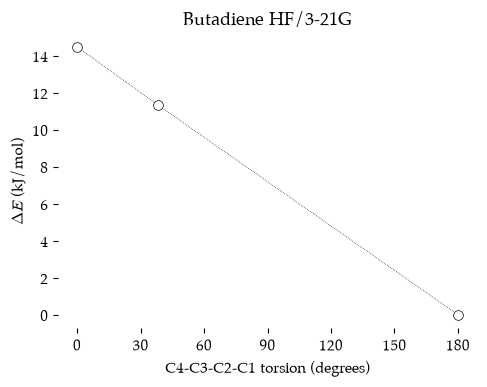

In [15]:
x = [0.0, dihedral(cis, 3, 2, 1, 0), 180.0]
y = np.array([E_cis_frozen, E_cis, E_trans])
y = (y - E_trans) * psi4.constants.hartree2kJmol

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(x, y, color="black", linewidth=0.5, linestyle=":", zorder=1)
ax.plot(x, y, linestyle="none", marker="o", markersize=7, markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_xlabel("C4-C3-C2-C1 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butadiene HF/3-21G")
plt.show()

### The Hypothesis

I have determined that there are **two stable conformers** (at least) at 38.15&deg; and 180&deg;. There will be a third conformer at &minus;38.15&deg; due to symmetry. I have a proposed **energy barrier** of rotation between the two *s-cis* forms at 38.15&deg; and &minus;38.15&deg; around the C&ndash;C bond in butadiene. The energy calculated when holding the torsion at 0&deg; is expected to be this barrier. The maximum electron stabilization occurs when &pi;-orbitals are parallel and it is at a minimum when &pi;-orbitals are at 90&deg;.

I therefore **hypothesize** that the energy barrier between the *s-cis* and *s-trans* forms will be at 90&deg;. Will the energy barrier be greater or less than the barrier due to steric strain at 0&deg;? It is time to perform an **experiment**.

### Experimental Design

I will perform the same geometry **optimization** calculations using a **frozen** torsion coordinate as before. I will choose 90&deg; for the angle and then run the calculation. I will **also** calculate torsion angles of 85&deg; and 95&deg; to ensure that I am at or near a maximum at 90&deg;.

In *GAMESS* the workflow was: 1) **change** the torsion angle in the input file; 2) **submit** the file to *GAMESS*; 3) **extract** the last energy value with *grep* and type it into a **list**; 4) repeat. In *Python*, we will put one constrained optimization in a **function** and call it in a **loop**. The `frozen_dihedral` option is still set. Each job writes its output file into a folder called `scan_HF321G`.

In [16]:
Path("scan_HF321G").mkdir(exist_ok=True)

def frozen_optimization(phi):
    psi4.core.clean()
    mol = make_butadiene(phi, tweak=5.0)
    psi4.set_output_file(f"scan_HF321G/butadiene_{phi:03d}.out", False)
    E, hist = psi4.optimize("hf/3-21g", molecule=mol, return_history=True)
    return E, len(hist["energy"]), mol

scan = []
molecules = {}

for phi in [85, 90, 95]:
    E, steps, mol = frozen_optimization(phi)
    scan.append({"Torsion (deg)": phi, "Energy (Eh)": E, "Steps": steps})
    molecules[phi] = mol
    print(f"{phi:4d} deg   {E:.10f} Hartree   {steps} steps")

Optimizer: Optimization complete!
  85 deg   -154.0513572702 Hartree   18 steps
Optimizer: Optimization complete!
  90 deg   -154.0509343220 Hartree   17 steps
Optimizer: Optimization complete!
  95 deg   -154.0506281059 Hartree   18 steps


| Line | Notes |
| :---- | :---- |
| `Path("scan_HF321G").mkdir(exist_ok=True)` | Makes a **folder** for the output files. `exist_ok=True` means no complaint if it is already there. |
| `def frozen_optimization(phi):` | One **constrained optimization** with the torsion frozen at `phi`. It returns the energy, the number of steps and the optimized molecule. |
| `psi4.core.clean()` | Tidies up the scratch files from the **previous** job before starting the next one. |
| `f"scan_HF321G/butadiene_{phi:03d}.out"` | The output file name. `{phi:03d}` writes the angle with three digits (`085`, `090`, `095`) so the files sort in order. |
| `scan.append({...})` | Adds one **row** of results (a dictionary) to the list `scan`. We will turn the list into a table later. |
| `molecules[phi] = mol` | Keeps each optimized **molecule**, filed under its angle. We will need one of them later. |

Here are the energies for 90&deg; and the two checks at 85&deg; and 95&deg; (*GAMESS*: &minus;154.0513571936, &minus;154.0509342723 and &minus;154.0506280903). Let us add them to the **plot** for the potential energy surface.

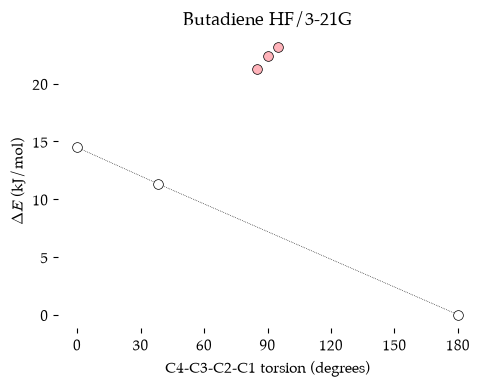

In [17]:
x2 = [row["Torsion (deg)"] for row in scan]
y2 = [(row["Energy (Eh)"] - E_trans) * psi4.constants.hartree2kJmol for row in scan]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(x, y, color="black", linewidth=0.5, linestyle=":", zorder=1)
ax.plot(x, y, linestyle="none", marker="o", markersize=7, markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.plot(x2, y2, linestyle="none", marker="o", markersize=7, markerfacecolor="#FFB3BA",
        markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_xlabel("C4-C3-C2-C1 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butadiene HF/3-21G")
plt.show()

Surprise! We are **not at a maximum**. The energy is still going **up** at 95&deg;. I will just keep changing the angle until we start coming back down, and while we are at it, fill in the whole profile. The loop does the typing.

In [18]:
angles = [5, 10, 20, 30, 35, 40, 45, 50, 60, 80, 100, 105, 110, 120, 140, 160, 170, 175, 180]

for phi in angles:
    E, steps, mol = frozen_optimization(phi)
    scan.append({"Torsion (deg)": phi, "Energy (Eh)": E, "Steps": steps})
    molecules[phi] = mol
    print(f"{phi:4d} deg   {E:.10f} Hartree   {steps} steps")

Optimizer: Optimization complete!
   5 deg   -154.0539921848 Hartree   21 steps
Optimizer: Optimization complete!
  10 deg   -154.0541309056 Hartree   22 steps
Optimizer: Optimization complete!
  20 deg   -154.0545762368 Hartree   19 steps
Optimizer: Optimization complete!
  30 deg   -154.0550028329 Hartree   17 steps
Optimizer: Optimization complete!
  35 deg   -154.0551183008 Hartree   16 steps
Optimizer: Optimization complete!
  40 deg   -154.0551324458 Hartree   17 steps
Optimizer: Optimization complete!
  45 deg   -154.0550306462 Hartree   18 steps
Optimizer: Optimization complete!
  50 deg   -154.0548093552 Hartree   18 steps
Optimizer: Optimization complete!
  60 deg   -154.0540449337 Hartree   21 steps
Optimizer: Optimization complete!
  80 deg   -154.0518629633 Hartree   18 steps
Optimizer: Optimization complete!
 100 deg   -154.0504706740 Hartree   18 steps
Optimizer: Optimization complete!
 105 deg   -154.0504892304 Hartree   20 steps
Optimizer: Optimization complete!
 110 d

Each job took between 16 and 26 steps. Now we gather everything into one **table**: the frozen 0&deg; job from before, the unconstrained *s-cis* minimum, and the scan. I have also typed in the energies from the *GAMESS* book for **comparison**.

In [19]:
scan.append({"Torsion (deg)": 0, "Energy (Eh)": E_cis_frozen, "Steps": len(hist_cis_frozen["energy"])})
scan.append({"Torsion (deg)": round(dihedral(cis, 3, 2, 1, 0), 2), "Energy (Eh)": E_cis,
             "Steps": len(hist_cis["energy"])})

profile = pd.DataFrame(scan).sort_values("Torsion (deg)").reset_index(drop=True)
profile["Delta E (kJ/mol)"] = (profile["Energy (Eh)"] - E_trans) * psi4.constants.hartree2kJmol

gamess = [-154.0539433, -154.0539921, -154.0541309, -154.0545762, -154.0550029, -154.0551183,
          -154.0551402, -154.0551325, -154.0550307, -154.0548094, -154.0540449, -154.0518630,
          -154.0513572, -154.0509343, -154.0506281, -154.0504706, -154.0504893, -154.0507019,
          -154.0517054, -154.0551449, -154.0582690, -154.0591535, -154.0593804, -154.0594778]
profile["GAMESS (Eh)"] = gamess

profile.to_json("butadiene_scan_HF321G.json", orient="records", indent=2)
profile.round({"Energy (Eh)": 8, "Delta E (kJ/mol)": 2})

,Torsion (deg),Energy (Eh),Steps,Delta E (kJ/mol),GAMESS (Eh)
0,0.00,-154.053943,19,14.47,-154.053943
1,5.00,-154.053992,21,14.35,-154.053992
2,10.00,-154.054131,22,13.98,-154.054131
3,20.00,-154.054576,19,12.81,-154.054576
4,30.00,-154.055003,17,11.69,-154.055003
5,35.00,-154.055118,16,11.39,-154.055118
6,38.15,-154.055140,20,11.33,-154.055140
7,40.00,-154.055132,17,11.35,-154.055133
8,45.00,-154.055031,18,11.62,-154.055031
9,50.00,-154.054809,18,12.20,-154.054809


| Line | Notes |
| :---- | :---- |
| `round(dihedral(cis, 3, 2, 1, 0), 2)` | The torsion of the unconstrained *s-cis* minimum, rounded to two decimals. |
| `.sort_values("Torsion (deg)")` | Puts the rows in **order** of angle. The jobs were run out of order. |
| `.reset_index(drop=True)` | Renumbers the rows 0, 1, 2… after sorting. |
| `profile["GAMESS (Eh)"] = gamess` | Adds the *GAMESS* energies as a new column. The list is in the same order of angles as the sorted table. |
| `profile.to_json(...)` | **Saves** the table as a JSON file beside this notebook. |

The *Psi4* and *GAMESS* energies **agree** to within 1 &times; 10<sup>&minus;7</sup> Hartree at every angle but one. At 180&deg; the *GAMESS* table has &minus;154.0594778 Hartree, 0.06 *kJ/mol* **lower** than our value and lower than the &minus;154.0594566 Hartree of its own unconstrained *s-trans* optimization. It probably came from a different job than the rest of the table. Our relative energies are therefore about 0.05 *kJ/mol* smaller than those in the *GAMESS* book, which used that value as its zero.

Now the **plot** of the complete profile.

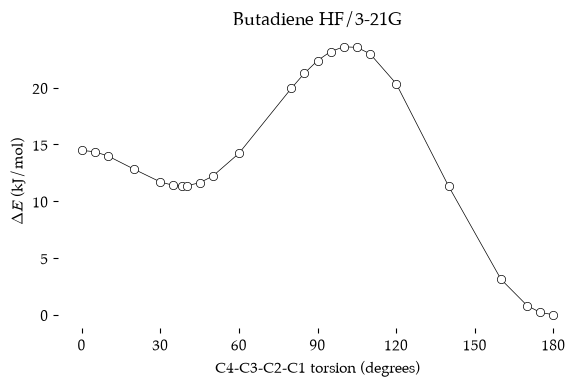

In [20]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(profile["Torsion (deg)"], profile["Delta E (kJ/mol)"], color="black",
        linewidth=0.5, zorder=1)
ax.plot(profile["Torsion (deg)"], profile["Delta E (kJ/mol)"], linestyle="none",
        marker="o", markersize=6, markerfacecolor="white", markeredgecolor="black",
        markeredgewidth=0.5, zorder=2)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_xlabel("C4-C3-C2-C1 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butadiene HF/3-21G")
plt.show()

I found that the energy value **peaks** near the 100&deg; point and then starts to decrease. The relative energies at 100&deg; and 105&deg; are 23.59 and 23.54 *kJ/mol*, and the energy at 110&deg; has fallen to 22.98 *kJ/mol*. The peak in energy occurs **somewhere** between 100&deg; and 105&deg;. The values at each angle are very close, so I **estimate** the maximum energy is about midway between, a little closer to 100&deg;.

```{figure} ../../images/Butadiene12.png
---
width: 500px
name: fig8-3
---
*The structures corresponding to the maxima and minima in the energy profile.*
```

Why is the maximum energy **found** at around 102&deg; rather than exactly 90&deg;? The **electronic** energy likely hits a maximum at 90&deg; and then starts to decrease as the angle rotates forward to 180&deg;. **Steric** repulsion from the other end of the molecule is still present and contributing to the total energy. It is decreasing as the angle opens up but results in an energy contribution that puts the maximum **nearer** to 100&deg; compared to 90&deg;. It seems that the steric interaction between the ends of the molecule pushed both stationary points to the right. The expected electronic minimum of 0&deg; was 38&deg; and the **expected** maximum of 90&deg; was >100&deg; when the steric effect is added in.

-----

## Finding A Transition State

The **peak** of the energy barrier, between a C&ndash;C torsion of 100&deg; and 105&deg;, is the **transition state** for converting between the *s-trans* and *s-cis* conformers of butadiene. Can we find the **exact point** at which we reach maximum energy along the path of change?

The coordinate that we are changing is the torsion angle along the central C&ndash;C bond. We have **scanned** that coordinate between 0&deg; and 180&deg;. Scanning in this way is a good way to get **close** to a transition state. Each scan point is an optimized structure for that given **torsion value**. So all other coordinates have been minimized in energy (we hope) for each step in the scan. In theory, we are following the **lowest energy path** (a valley) uphill and down over a **saddle point** (a mountain pass). The saddle point is the transition state. There is one direction (coordinate) that takes you **up and then down** in energy as the saddle point is crossed. All other coordinates will only take you uphill (assuming that they are at minimum energy values after optimization).

```{figure} ../../images/Butadiene13.png
---
width: 450px
name: fig8-4
---
*An example of a saddle point in a potential energy surface for a reaction {cite:p}`saddle_point_svg`.*
```

It is easy for *Psi4* to find a **minimum**. It just follows every gradient downward. It is more challenging to find a **saddle point**, where one coordinate is maximized and all others are minimized. How do you find that balance point?

*Psi4*'s optimizer can do this when we set the option `opt_type` to `ts` (the *GAMESS* equivalent is `RUNTYP=SADPOINT`). However, it needs to know what coordinate to follow to find the saddle point. The best way to do this is to construct a structure that is **close** to a hypothetical saddle point (our optimized scan structure for 100&deg; seems like a good starting point).

### Finding The Imaginary Vibration

*Psi4* still needs **lots of help**. First we need an **imaginary vibration** to follow. So we will have to perform a vibration calculation first. The imaginary vibration is often designated with a negative frequency. It is a vibration that moves along the **reaction coordinate**. All normal vibrations increase in energy as they move away from their centre points. The imaginary vibration is at a maximum at its centre. It is going downhill toward starting material or product as it **moves away** from the center.

A **structure** that is optimized (except for the frozen coordinate) and is very near the transition state structure should have an imaginary vibration. We need to perform a **vibration calculation** first. That means calculating the **Hessian** matrix, the second derivatives of the energy with respect to every pair of atomic coordinates. The **vibrations** and their **frequencies** come out of the Hessian. With higher levels of theory this can take a long time, but we are using a very low level of theory and won't have to wait long. In many cases 3-21G will not be suitable for an accurate **transition state** in a reaction but, since we are not making or breaking bonds, we should be OK.

We must first **clear** the `frozen_dihedral` option. Then we take a **copy** of the 100&deg; structure from the scan and calculate its frequencies (`RUNTYP=HESSIAN` in *GAMESS*). We will also ask *Psi4* to write the vibrations to a file that *Avogadro* can display.

In [21]:
psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk",
                  "normal_modes_write": True,
                  "writer_file_label": "butadiene_ts_guess"})

ts = molecules[100].clone()
print(f"Starting C4-C3-C2-C1 torsion: {dihedral(ts, 3, 2, 1, 0):.2f} degrees")

psi4.set_output_file("butadiene_ts_guess_freq.out", False)

E_guess, wfn_guess = psi4.frequency("hf/3-21g", molecule=ts, return_wfn=True)

freqs_guess = wfn_guess.frequencies().to_array()
print(f"Energy: {E_guess:.8f} Hartree")
print("Frequencies (cm-1):")
print(np.round(freqs_guess, 2))

Starting C4-C3-C2-C1 torsion: 100.00 degrees
Energy: -154.05047067 Hartree
Frequencies (cm-1):
[-165.26000000  374.63000000  403.54000000  731.88000000  787.72000000
  924.85000000 1115.78000000 1122.58000000 1150.30000000 1152.47000000
 1201.21000000 1265.34000000 1461.59000000 1463.78000000 1587.83000000
 1622.84000000 1828.32000000 1864.91000000 3305.89000000 3306.63000000
 3319.08000000 3323.45000000 3391.76000000 3392.09000000]


| Line | Notes |
| :---- | :---- |
| `psi4.core.clean_options()` | Clears **all** the options, including `frozen_dihedral`. We then set `scf_type` again. |
| `"normal_modes_write": True` | Writes the vibrations to a *Molden* file that ends in `.molden_normal_modes`. |
| `"writer_file_label": "butadiene_ts_guess"` | The **start** of that file's name. *Psi4* adds a number (the process ID) and `.molden_normal_modes`, for example `butadiene_ts_guess.1260.molden_normal_modes`. |
| `molecules[100].clone()` | A **copy** of the optimized 100&deg; molecule from the scan. We will change the copy and leave the original alone. |
| `psi4.frequency("hf/3-21g", ...)` | Calculates the **Hessian** and the vibrational frequencies. `return_wfn=True` gives us the wavefunction, which holds the results. |
| `wfn_guess.frequencies().to_array()` | The vibrational **frequencies** in cm<sup>&minus;1</sup>. Imaginary frequencies are shown as **negative** numbers. |

There are 24 vibrations (3N &minus; 6 = 24 for 10 atoms). *GAMESS* also listed six near-zero "frequencies" for the translations and rotations of the whole molecule. *Psi4* removes those. We observe a single **imaginary** frequency, 165.26*i* cm<sup>&minus;1</sup> (*GAMESS*: 167.05*i*). Don't trust the numbers too much but I am impressed that we are within the ball park. For example, the C&ndash;H stretch frequencies should be in the 3040-3100 cm<sup>&minus;1</sup> range and the calculation finds them between 3306 and 3392 cm<sup>&minus;1</sup>. Not bad.

Here is the imaginary vibration. Is it the bond **rotation** that we expect?

In [22]:
show_vibration(wfn_guess, 0)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

The two ends of the molecule **twist** about the central C&ndash;C bond. The vectors are as expected for bond rotation, so I think we have a **good starting point** for a saddle point optimization. You can also open the `butadiene_ts_guess` file that ends in `.molden_normal_modes` in *Avogadro* to see every vibration and its arrows.

### Calculating The Saddle Point

Now that we know we have an acceptable **imaginary frequency** in our structure we can conduct a saddle point optimization calculation. In *GAMESS* I set `RUNTYP=SADPOINT` and `HESS=CALC`, which runs a **saddle point optimization** using a newly calculated Hessian matrix. I also set the optimization tolerance to `OPTTOL=0.00001`, which is ten-fold **tighter** than for a typical optimization. The *Psi4* options are below.

In [23]:
psi4.core.clean()
psi4.set_options({"normal_modes_write": False,
                  "opt_type": "ts",
                  "full_hess_every": 0,
                  "g_convergence": "gau_tight"})

psi4.set_output_file("butadiene_ts.out", False)

E_ts, hist_ts = psi4.optimize("hf/3-21g", molecule=ts, return_history=True)

print(f"Final energy: {E_ts:.8f} Hartree")
print("Steps taken: ", len(hist_ts["energy"]))
print(f"C4-C3-C2-C1 torsion: {dihedral(ts, 3, 2, 1, 0):.2f} degrees")
print(f"C1-C2-C3 angle: {bond_angle(ts, 0, 1, 2):.2f} degrees")
print(f"C2-C3 bond: {bond_length(ts, 1, 2):.4f} Angstrom")

Optimizer: Optimization complete!
Final energy: -154.05045573 Hartree
Steps taken:  3
C4-C3-C2-C1 torsion: 102.02 degrees
C1-C2-C3 angle: 123.75 degrees
C2-C3 bond: 1.4905 Angstrom


| Line | Notes |
| :---- | :---- |
| `"opt_type": "ts"` | Search for a **transition state** (a saddle point) instead of a minimum. The optimizer goes **uphill** along one direction and downhill along all the others. This is `RUNTYP=SADPOINT` in *GAMESS*. |
| `"full_hess_every": 0` | Calculate the full **Hessian** once, at the start, and then update it with the gradients at each step. This is `HESS=CALC` with the default `IHREP=0` in *GAMESS*. |
| `"g_convergence": "gau_tight"` | A **tighter** set of convergence criteria: the largest force must be below 1.5 &times; 10<sup>&minus;5</sup> and the largest displacement below 6.0 &times; 10<sup>&minus;5</sup>, among others. This plays the role of the tighter `OPTTOL=0.00001`, although the two tests are not defined the same way. |

The calculation completed without errors in 3 steps. The energy is &minus;154.05045573 Hartree (*GAMESS*: &minus;154.0504557511 after 2 steps). Notice that the energy went **up** slightly from the starting structure (&minus;154.05047067 Hartree). That is what we want. We are climbing to the top of the pass. In the convergence table below, all four force and displacement criteria of `gau_tight` were met (`*`) at step 3.

Let us see the final structure in the output file.

In [24]:
search_file("butadiene_ts.out", "~")

with open("butadiene_ts.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 18]))

  1657: 	----------------------------------------------------------------------------------------------~
  1658: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
  1659: 	----------------------------------------------------------------------------------------------~
  1660: 	  Convergence Criteria              o    1.50e-05 *    1.00e-05 *    6.00e-05 *    4.00e-05 *~
  1661: 	----------------------------------------------------------------------------------------------~
  1662: 	     1    -154.05047067   -1.54e+02 o    4.11e-04      1.03e-04      4.98e-02      1.51e-02    ~
  2117: 	     2    -154.05045573    1.49e-05 o    3.04e-05      6.81e-06 *    4.67e-04      1.56e-04    ~
  2568: 	     3    -154.05045573   -2.33e-09 o    3.27e-07 *    7.08e-08 *    1.02e-06 *    4.38e-07 *  ~
    Final optimized geometry and variables:
    Molecular point group: c1
    Full point group: C1

    Geometry (in Angstrom), charge = 0, multiplicity = 1:


The calculation has determined that a **saddle point** exists when the C&ndash;C torsion angle (the 4,3,2,1 torsion) is 102.02&deg;. The C=C bonds are 1.3162 &Aring;, the central C&ndash;C bond has stretched to 1.4905 &Aring; (from 1.4674 &Aring; in the *s-trans* conformer) and the C&ndash;C&ndash;C angles are 123.75&deg;. *GAMESS* found 1.3162 &Aring;, 1.4905 &Aring;, 123.75&deg; and 102.02&deg;. The longer central bond makes sense. With the &pi; bonds at right angles, there is no conjugation to give the central bond some double-bond character.

### Is It Really a Transition State?

A true transition state has exactly **one** imaginary frequency. *GAMESS* did not check this for us, but it costs very little to make sure. We clear the options and calculate the frequencies at the new structure.

In [25]:
psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})

psi4.set_output_file("butadiene_ts_freq.out", False)

E_ts_freq, wfn_ts = psi4.frequency("hf/3-21g", molecule=ts, return_wfn=True)

freqs_ts = wfn_ts.frequencies().to_array()
print("Imaginary frequencies:", freqs_ts[freqs_ts < 0])
print("Lowest five:          ", np.round(freqs_ts[:5], 2))
search_file("butadiene_ts_freq.out", "Freq [cm^-1]")

Imaginary frequencies: [-167.93758563]
Lowest five:           [-167.94000000  378.54000000  399.91000000  726.69000000  790.91000000]
  1317:   Freq [cm^-1]                167.9376i            378.5385            399.9089
  1338:   Freq [cm^-1]                 726.6879            790.9084            924.7053
  1359:   Freq [cm^-1]                1116.2058           1122.0535           1150.6920
  1380:   Freq [cm^-1]                1151.8270           1198.6739           1268.9028
  1401:   Freq [cm^-1]                1462.1855           1463.6389           1587.0734
  1422:   Freq [cm^-1]                1623.0400           1827.2193           1865.4120
  1443:   Freq [cm^-1]                3306.0243           3307.2830           3319.0075
  1464:   Freq [cm^-1]                3323.3255           3391.4288           3391.7068


| Line | Notes |
| :---- | :---- |
| `freqs_ts[freqs_ts < 0]` | Only the **negative** (imaginary) frequencies. `freqs_ts < 0` is a list of `True`/`False` values that picks them out. |

There is exactly **one** imaginary frequency, 167.94*i* cm<sup>&minus;1</sup>, and all the others are real. We have a **transition state**.

### The Complete Profile

Now we can add the transition state to our potential energy surface. Here is the complete table with the **stationary points** (maxima and minima) marked, and the plot.

In [26]:
ts_row = pd.DataFrame([{"Torsion (deg)": round(dihedral(ts, 3, 2, 1, 0), 2), "Energy (Eh)": E_ts,
                        "Steps": len(hist_ts["energy"]), "GAMESS (Eh)": -154.0504558}])
profile = pd.concat([profile, ts_row]).sort_values("Torsion (deg)").reset_index(drop=True)
profile["Delta E (kJ/mol)"] = (profile["Energy (Eh)"] - E_trans) * psi4.constants.hartree2kJmol

stationary = [0.0, round(dihedral(cis, 3, 2, 1, 0), 2), round(dihedral(ts, 3, 2, 1, 0), 2), 180.0]
profile["Stationary"] = profile["Torsion (deg)"].isin(stationary)

profile.to_json("butadiene_scan_HF321G.json", orient="records", indent=2)
profile.round({"Energy (Eh)": 8, "Delta E (kJ/mol)": 2})

,Torsion (deg),Energy (Eh),Steps,Delta E (kJ/mol),GAMESS (Eh),Stationary
0,0.00,-154.053943,19,14.47,-154.053943,True
1,5.00,-154.053992,21,14.35,-154.053992,False
2,10.00,-154.054131,22,13.98,-154.054131,False
3,20.00,-154.054576,19,12.81,-154.054576,False
4,30.00,-154.055003,17,11.69,-154.055003,False
5,35.00,-154.055118,16,11.39,-154.055118,False
6,38.15,-154.055140,20,11.33,-154.055140,True
7,40.00,-154.055132,17,11.35,-154.055133,False
8,45.00,-154.055031,18,11.62,-154.055031,False
9,50.00,-154.054809,18,12.20,-154.054809,False


| Line | Notes |
| :---- | :---- |
| `pd.concat([profile, ts_row])` | Adds the transition state **row** to the bottom of the table. Then we sort again. |
| `profile["Torsion (deg)"].isin(stationary)` | A new column that is `True` for the four **stationary points**: the frozen 0&deg; maximum, the *s-cis* minimum, the transition state and the *s-trans* minimum. |

We saved the table again, now with the transition state, as `butadiene_scan_HF321G.json`.

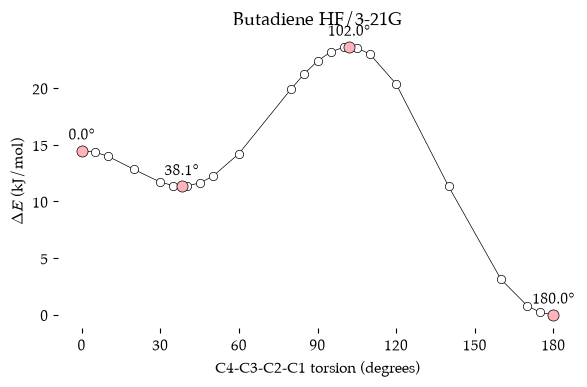

In [27]:
points = profile[profile["Stationary"]]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(profile["Torsion (deg)"], profile["Delta E (kJ/mol)"], color="black",
        linewidth=0.5, zorder=1)
ax.plot(profile["Torsion (deg)"], profile["Delta E (kJ/mol)"], linestyle="none",
        marker="o", markersize=6, markerfacecolor="white", markeredgecolor="black",
        markeredgewidth=0.5, zorder=2)
ax.plot(points["Torsion (deg)"], points["Delta E (kJ/mol)"], linestyle="none",
        marker="o", markersize=8, markerfacecolor="#FFB3BA", markeredgecolor="black",
        markeredgewidth=0.5, zorder=3)
for xi, yi in zip(points["Torsion (deg)"], points["Delta E (kJ/mol)"]):
    ax.annotate(f"{xi:.1f}°", (xi, yi), textcoords="offset points",
                xytext=(0, 8), ha="center")
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_xlabel("C4-C3-C2-C1 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butadiene HF/3-21G")
plt.show()

| Line | Notes |
| :---- | :---- |
| `profile[profile["Stationary"]]` | Only the rows where `Stationary` is `True`. |
| `markerfacecolor="#FFB3BA"` | The stationary points are drawn **larger**, in pastel red, on top of the other points. |
| `ax.annotate(...)` | Writes the torsion angle above each stationary point. |

I had hypothesized that the transition state for bond rotation would occur between 100&deg; and 105&deg; and a little closer to 100&deg; than 105&deg;. I chose 102&deg; to make the diagram in {numref}`fig8-3`. *Psi4* proposes that the transition state occurs at 102.02&deg;. Great minds think alike.

-----

## From Energies to Equilibrium and Rate

We promised at the start to **estimate** an equilibrium constant and a rate. The energy difference between the *s-cis* and *s-trans* conformers gives the equilibrium constant, $K = e^{-\Delta E / RT}$. There are **two** *s-cis* conformers (at +38&deg; and &minus;38&deg;), mirror images of each other, so the *s-cis* side of the equilibrium gets a factor of 2. The energy barrier gives the rate constant through the **Eyring equation**, $k = \frac{k_B T}{h} e^{-\Delta E^\ddagger / RT}$.

In [28]:
R = 8.314462618e-3      # kJ/(mol K)
kB = 1.380649e-23       # J/K
h = 6.62607015e-34      # J s
T = 298.15              # K

dE_cis = (E_cis - E_trans) * psi4.constants.hartree2kJmol
dE_ts = (E_ts - E_trans) * psi4.constants.hartree2kJmol
dE_ts_cis = (E_ts - E_cis) * psi4.constants.hartree2kJmol

K = 2 * np.exp(-dE_cis / (R * T))
k_forward = (kB * T / h) * np.exp(-dE_ts / (R * T))
k_reverse = (kB * T / h) * np.exp(-dE_ts_cis / (R * T))

print(f"s-cis - s-trans:      {dE_cis:.2f} kJ/mol")
print(f"Barrier from s-trans: {dE_ts:.2f} kJ/mol")
print(f"Barrier from s-cis:   {dE_ts_cis:.2f} kJ/mol")
print(f"K = [s-cis]/[s-trans] = {K:.4f}   ({100 * K / (1 + K):.1f}% s-cis)")
print(f"k(s-trans -> s-cis) = {k_forward:.2e} per second")
print(f"k(s-cis -> s-trans) = {k_reverse:.2e} per second")

s-cis - s-trans:      11.33 kJ/mol
Barrier from s-trans: 23.63 kJ/mol
Barrier from s-cis:   12.30 kJ/mol
K = [s-cis]/[s-trans] = 0.0207   (2.0% s-cis)
k(s-trans -> s-cis) = 4.50e+08 per second
k(s-cis -> s-trans) = 4.35e+10 per second


| Line | Notes |
| :---- | :---- |
| `R`, `kB`, `h` | The gas constant, the Boltzmann constant and the Planck constant. |
| `100 * K / (1 + K)` | The **percentage** of molecules that are *s-cis*. |

At room temperature, about 2% of butadiene molecules are *s-cis* by this estimate. The barrier from the *s-trans* side is 23.63 *kJ/mol*, and the rate constant for rotation is about 4.5 &times; 10<sup>8</sup> per second. Each molecule flips from *s-trans* to *s-cis* hundreds of millions of times a second. There **is** a barrier to rotation, but it is easily crossed at room temperature. You could never isolate the two conformers in a bottle.

```{warning}
These are **rough** estimates. We used the electronic energies only, from a low level of theory, in gas phase. A proper calculation would use free energies that include the **zero-point** vibrational energy and the **entropy**, which *Psi4* reports at the end of a frequency calculation. We have the frequencies for the transition state, so you could try it (see the exercise).
```

-----

## Summary

These are the operations that we have performed over the course of this activity.

1.	**Build and Optimize** symmetrical butadiene. We calculated the optimized geometry of butadiene using an initial structure that was perfectly flat for the *s-cis* conformer and the *s-trans* conformer. The calculation easily found the bond lengths and angles for minimum energy but was trapped in stationary points for the torsion coordinates due to the flat symmetry.
2.	**Read** the output file. We found the point group, the basis set, the energy at each step, the convergence table and the final structure in the *Psi4* output file.
3.	**Optimize** the asymmetrical structures of butadiene. We then started from a slightly randomized structure and found that the minimum for the *s-cis* conformer actually occurred when the C&ndash;C torsion was 38&deg;. We also saw that the *s-trans* conformer did indeed find an almost flat optimized structure.
4.	Scan the torsion angle to create an **energy profile**. We then performed a series of optimization calculations with the torsion coordinate for the &sigma; C&ndash;C bond frozen over a set of angles. This allowed us to observe that the transition state for rotation between *s-cis* and *s-trans* conformers was near a torsion angle of 102&deg;.
5.	Evaluate the **vibrations** near the transition state. I used a structure from the torsion scan to calculate the vibrations in a structure that was close to the hypothesized transition state. This was to confirm that there was an imaginary vibration that would likely take us toward the true transition state.
6.	Calculate an optimized **structure** for the **transition state**. After confirming that we had a good imaginary vibration, I performed a saddle point calculation that optimized the structure for the nearest transition state. We were very close already and found it easily. The T.S. was at a torsion angle of 102.0&deg;, and a frequency calculation confirmed that it has exactly one imaginary vibration.
7.	**Estimate** the equilibrium constant and the rate of rotation from the energies.

## Exercise

### The Activities

Here are some activities that you can perform to **increase** your understanding of using *Psi4* to calculate potential energy profiles and transition states for bond rotations.

Calculate the **rotational** energy profile for **ethane** and for the C&ndash;C bond of propane. Compare the energy barriers between them and also with the butadiene and butane calculations. How does a steric energy barrier in ethane compare to that of butane? How does the electronic **cost** of **breaking** the conjugation in butadiene compare to breaking the C=C bond in ethylene?

Calculate the energy profile for **rotating** ethylene across the C=C double bond. What is the energy cost of effectively breaking a &pi;-bond during a bond rotation? **Compare** that to the cost of breaking the conjugation in butadiene.

**Going further:** Find the transition state for the rotation between the two *s-cis* conformers. Is the flat 0&deg; structure a true transition state? Calculate its frequencies and count the imaginary ones.

````{admonition} Hint: a transition state for ethylene
:class: dropdown
A twisted ethylene (90&deg;) has its two &pi; electrons in two orthogonal *p* orbitals. That is a **diradical**, and a closed-shell RHF calculation describes it badly. Compare the energy of the RHF singlet with a triplet (`0 3` on the first line of the geometry and `"reference": "uhf"`). Which is lower at 90&deg;?
````

````{admonition} Hint: free energies
:class: dropdown
After a frequency calculation, *Psi4* prints a thermochemistry section at the end of the output file. Look for it with `search_file()`.

```python
search_file("butadiene_ts_freq.out", "Total G, Free enthalpy at  298.15 [K]")
```

You will need a frequency calculation at the *s-trans* and *s-cis* minima too.
````

### The Report

Present a ONE PAGE **document** with a table of angles and energies for the maxima and minima of the rotational profile of butadiene, ethylene and one other molecule of your choice. Include a plot of the energy profiles and **comment** on how the barriers compare.

Please **report the time** it took to set up and run the calculations. The table and plot must be professional in appearance.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Butadiene" chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **a third** of the text is **my own work**, carried over word for word or lightly edited (typos fixed, and references to *GAMESS*, *MacMolPlt* and *grep* changed where *Psi4* and *Python* now do the job). My text includes the introduction, the description of how an optimization follows the gradient downhill, the flat *s-cis* trap and breaking the symmetry, the compromise between conjugation and steric clash, the comparison of the tweaked and flat structures, freezing a coordinate, the hypothesis and experimental design, the explanation of why the barrier is near 102&deg; rather than 90&deg;, the description of saddle points and imaginary vibrations, most of the summary, and the challenges. The figures of the optimized structures, the conformer drawings and the saddle point are also mine, from the previous book. The **rest of the page** was written by an **LLM system** at my request. I asked it to convert the *GAMESS* jobs to *Python* code for *Psi4* at the HF/3-21G level, to replace the *MacMolPlt* and *Unix* sections with *Python*, and to compare the results with the *GAMESS* calculations. The LLM wrote all of the *Python* code and the line-by-line explanations of it, the learning goals, the note on the 3-21G basis set, the tour of the output file, the use of explicit symmetry for the flat structures, the scan loop and the comparison table, the frequency check of the transition state, the animation of the imaginary vibration, the section on the equilibrium and rate constants, the hints and the report, and the commentary on all of the results. I ran every calculation on my own computer, and the numbers quoted in the text come from those results.
```